In [5]:
import pandas as pd
import numpy as np

# Загрузка датасета
df = pd.read_csv("mit_oai_with_ner_keywords.csv")

# Фильтрация по ORCID
df_with_orcid = df.dropna(subset=["orcid"]).copy()
df_without_orcid = df[df["orcid"].isna()].copy()

# Функция для фильтрации по уверенности (3 сигмы)
def filter_by_confidence(df, col_name, threshold_type="ner"):
    if threshold_type == "ner":
        scores = []
        for entities_str in df[col_name]:
            if pd.notna(entities_str):
                for entity in entities_str.split("; "):
                    try:
                        _, _, score = entity.split("|")
                        scores.append(float(score))
                    except:
                        pass
        if not scores:
            return df
        mean_score = np.mean(scores)
        std_score = np.std(scores)
        lower_bound = mean_score - 3 * std_score
        upper_bound = mean_score + 3 * std_score
    else:
        lower_bound = 0.05

    filtered_entities = []
    for entities_str in df[col_name]:
        if pd.isna(entities_str):
            filtered_entities.append("")
            continue
        filtered_list = []
        for entity in entities_str.split("; "):
            try:
                if threshold_type == "ner":
                    word, label, score = entity.split("|")
                    if lower_bound <= float(score) <= upper_bound:
                        filtered_list.append(f"{word}|{label}|{score}")
                else:
                    keyword, score = entity.split("|")
                    if float(score) >= lower_bound:
                        filtered_list.append(f"{keyword}|{score}")
            except:
                pass
        filtered_entities.append("; ".join(filtered_list))

    df[col_name] = filtered_entities
    return df

# Применяем фильтрацию
df_with_orcid = filter_by_confidence(df_with_orcid, "ner_entities", "ner")
df_with_orcid = filter_by_confidence(df_with_orcid, "keywords", "keyword")
df_without_orcid = filter_by_confidence(df_without_orcid, "ner_entities", "ner")
df_without_orcid = filter_by_confidence(df_without_orcid, "keywords", "keyword")

# Сохраняем в отдельные файлы
df_with_orcid.to_csv("articles_with_orcid_filtered.csv", index=False)
df_without_orcid.to_csv("articles_without_orcid_filtered.csv", index=False)

print("Файлы сохранены:")
print("- articles_with_orcid_filtered.csv")
print("- articles_without_orcid_filtered.csv")

Файлы сохранены:
- articles_with_orcid_filtered.csv
- articles_without_orcid_filtered.csv


In [6]:
from collections import defaultdict

# Группировка по ORCID
author_profiles = defaultdict(lambda: {"ner": defaultdict(int), "keywords": defaultdict(int)})

# Парсим NER и ключевые слова
for _, row in df_with_orcid.iterrows():
    orcid = row["orcid"]
    creators_str = row.get("creators", "")
    if pd.isna(creators_str) or not isinstance(creators_str, str):
        creators = []
    else:
        creators = [a.strip() for a in creators_str.split(",") if a.strip()]

    # Парсим NER
    if pd.notna(row["ner_entities"]) and isinstance(row["ner_entities"], str):
        for entity in row["ner_entities"].split("; "):
            if not entity:
                continue
            try:
                word, label, score = entity.split("|")
                author_profiles[orcid]["ner"][word] += 1
            except:
                pass

    # Парсим ключевые слова
    if pd.notna(row["keywords"]) and isinstance(row["keywords"], str):
        for kw in row["keywords"].split("; "):
            if not kw:
                continue
            try:
                keyword, score = kw.split("|")
                author_profiles[orcid]["keywords"][keyword] += 1
            except:
                pass

# Конвертируем в DataFrame
author_stats = []
for orcid, data in author_profiles.items():
    author_stats.append({
        "orcid": orcid,
        "num_ner": len(data["ner"]),
        "num_keywords": len(data["keywords"]),
        "ner_stats": data["ner"],
        "keyword_stats": data["keywords"]
    })

author_df = pd.DataFrame(author_stats)
author_df.to_csv("author_profiles.csv", index=False)

# Вывод статистик
print("\nСтатистика по авторам:")
print(f"Всего авторов с ORCID: {len(author_df)}")
print(f"Среднее число NER на автора: {author_df['num_ner'].mean():.2f}")
print(f"Медиана числа NER на автора: {author_df['num_ner'].median()}")
print(f"Среднее число ключевых слов на автора: {author_df['num_keywords'].mean():.2f}")
print(f"Медиана числа ключевых слов на автора: {author_df['num_keywords'].median()}")

# Пример: Топ-5 авторов по числу NER
top_ner_authors = author_df.nlargest(5, 'num_ner')
print("\nТоп-5 авторов по числу именованных сущностей:")
print(top_ner_authors[["orcid", "num_ner"]])

# Пример: Топ-5 авторов по числу ключевых слов
top_keywords_authors = author_df.nlargest(5, 'num_keywords')
print("\nТоп-5 авторов по числу ключевых слов:")
print(top_keywords_authors[["orcid", "num_keywords"]])


Статистика по авторам:
Всего авторов с ORCID: 5770
Среднее число NER на автора: 26.12
Медиана числа NER на автора: 10.0
Среднее число ключевых слов на автора: 36.55
Медиана числа ключевых слов на автора: 10.0

Топ-5 авторов по числу именованных сущностей:
                                     orcid  num_ner
56   https://orcid.org/0000-0002-7586-7253     1891
300  https://orcid.org/0000-0002-6047-4211     1363
27   https://orcid.org/0000-0002-3831-9071     1217
233  https://orcid.org/0000-0003-0293-1944     1045
244  https://orcid.org/0000-0001-8285-3346     1035

Топ-5 авторов по числу ключевых слов:
                                     orcid  num_keywords
56   https://orcid.org/0000-0002-7586-7253          3131
27   https://orcid.org/0000-0002-3831-9071          1976
300  https://orcid.org/0000-0002-6047-4211          1899
233  https://orcid.org/0000-0003-0293-1944          1632
244  https://orcid.org/0000-0001-8285-3346          1263


In [7]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Функция для генерации облака слов
def generate_wordcloud(text_data, title, output_file):
    text = " ".join(text_data)
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(title)
    plt.axis('off')
    plt.savefig(output_file, bbox_inches='tight', dpi=200)
    plt.close()

# Облако слов для именованных сущностей (только слова, без типов)
all_ner_words = []
for ner_str in df_with_orcid["ner_entities"]:
    if pd.notna(ner_str) and isinstance(ner_str, str):
        for entity in ner_str.split("; "):
            try:
                word, _, _ = entity.split("|")
                all_ner_words.append(word)
            except:
                pass

generate_wordcloud(all_ner_words, "Облако именованных сущностей", "ner_words_wordcloud.png")

# Облако ключевых слов
all_keywords = []
for keywords_str in df_with_orcid["keywords"]:
    if pd.notna(keywords_str) and isinstance(keywords_str, str):
        for kw in keywords_str.split("; "):
            try:
                keyword, _ = kw.split("|")
                all_keywords.append(keyword)
            except:
                pass

generate_wordcloud(all_keywords, "Облако ключевых слов", "keyword_wordcloud.png")

print("\nОблака слов сохранены:")
print("- ner_words_wordcloud.png (только слова NER)")
print("- keyword_wordcloud.png")


Облака слов сохранены:
- ner_words_wordcloud.png (только слова NER)
- keyword_wordcloud.png



Статистика по NER:
Среднее число NER на автора: 26.12
Медиана числа NER на автора: 10.00
Максимум: 1891
Минимум: 0


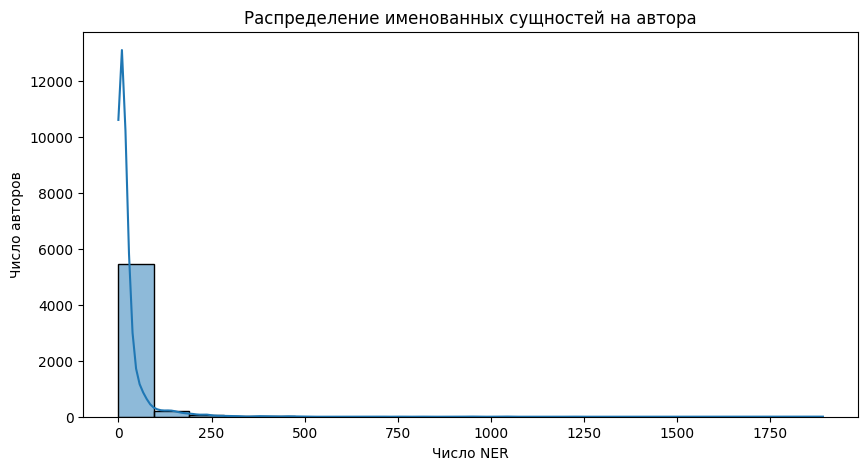


Сводная статистика сохранена в author_stats_summary.csv


In [8]:
# Статистика NER на автора
author_df["avg_ner_per_author"] = author_df["num_ner"]
author_df["avg_keywords_per_author"] = author_df["num_keywords"]

# Вывод статистик
print("\nСтатистика по NER:")
print(f"Среднее число NER на автора: {author_df['avg_ner_per_author'].mean():.2f}")
print(f"Медиана числа NER на автора: {author_df['avg_ner_per_author'].median():.2f}")
print(f"Максимум: {author_df['avg_ner_per_author'].max()}")
print(f"Минимум: {author_df['avg_ner_per_author'].min()}")

# Пример: гистограмма распределения NER на автора
plt.figure(figsize=(10, 5))
sns.histplot(author_df["avg_ner_per_author"], bins=20, kde=True)
plt.title("Распределение именованных сущностей на автора")
plt.xlabel("Число NER")
plt.ylabel("Число авторов")
plt.show()

# Сохранение статистик
stats_summary = {
    "total_authors": len(author_df),
    "avg_ner_per_author": author_df["avg_ner_per_author"].mean(),
    "median_ner_per_author": author_df["avg_ner_per_author"].median(),
    "avg_keywords_per_author": author_df["avg_keywords_per_author"].mean(),
    "median_keywords_per_author": author_df["avg_keywords_per_author"].median()
}
pd.DataFrame([stats_summary]).to_csv("author_stats_summary.csv", index=False)
print("\nСводная статистика сохранена в author_stats_summary.csv")